# Pauli noise simulation

Real quantum computers are noisy. In this tutorial you will learn how to describe the noise of a device with a `NoiseModel`, how to compute noisy expectation values with the HSMPO surrogate, how to check them against an exact density-matrix simulation, and how to sweep the noise strength. Along the way, we explain how mpstab simulates Pauli noise without ever building a density matrix.

## Setup

Besides `mpstab`, we use qibo for the gate types and matplotlib for the plots. `set_style()` applies the plot style shared by all mpstab tutorials.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import (
    HSMPO,
    CoherentError,
    DepolarizingError,
    NoiseModel,
    PauliError,
    ReadoutError,
    pauli_string_to_hamiltonian,
)
from mpstab.models.ansatze import ParametricKickedIsing
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()

## The circuit

We simulate three steps of a kicked Ising chain on 8 qubits. Its Clifford skeleton is maximally entangling, and `delta_h` moves the transverse kicks away from Clifford, adding magic. The Ising couplings are compiled as `CNOT · RZ · CNOT`, so the two-qubit gates are CNOTs. We measure the nearest-neighbour energy $H = \sum_i Z_i Z_{i+1}$.

In [2]:
NQUBITS = 8

ansatz = ParametricKickedIsing(nqubits=NQUBITS, n_steps=3, delta_h=0.2)
circuit = ansatz.circuit


def zz(i, n=NQUBITS):
    return "".join("Z" if q in (i, i + 1) else "I" for q in range(n))


energy = {zz(i): 1.0 for i in range(NQUBITS - 1)}

hsmpo = HSMPO(ansatz, progress=False)
ideal = hsmpo.expectation(energy)
print(f"{len(circuit.queue)} gates, {hsmpo.n_magic_gates} magic gates")
print(f"noiseless <H> = {ideal:+.5f}")

111 gates, 24 magic gates
noiseless <H> = +0.56761


## Building a noise model

A `NoiseModel` is built rule by rule, as in qibo. `noise.add(error, gate, qubits)` puts `error` right after every gate of type `gate` (every gate if omitted), optionally only on some qubits. Four kinds of errors cover most needs:

| error | what it describes |
|---|---|
| `PauliError({"X": p, ...})` | random Pauli flips; a label as wide as the gate (`"ZZ"`) acts jointly on its qubits |
| `DepolarizingError(lam)` | depolarizing channel on the gate's qubits |
| `CoherentError("ZZ", angle)` | a small unwanted rotation $e^{-i\,\text{angle}\,P/2}$, such as a residual coupling |
| `ReadoutError(p)` | bit flips of the measured outcomes |

In [3]:
noise = NoiseModel()
noise.add(PauliError({"X": 3e-4, "Y": 3e-4, "Z": 3e-4}))      # every gate
noise.add(DepolarizingError(2e-3), gates.CNOT)                # two-qubit gate error
noise.add(PauliError({"ZZ": 1e-3}), gates.CNOT)               # correlated dephasing
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)              # residual ZZ coupling
noise.add(CoherentError("X", 0.01), gates.RX, qubits=[0, 1])  # over-rotation on two qubits

print(len(noise.events(circuit)), "errors inserted in the circuit")

291 errors inserted in the circuit


## Noisy expectation values

`hsmpo.noisy_expectation` sits next to `hsmpo.expectation`. It returns a `NoisyExpectation`, with the value in `mean` and its statistical error in `stderr`.

In [4]:
start = time.perf_counter()
result = hsmpo.noisy_expectation(energy, noise, n_samples=1000, seed=0)
elapsed = time.perf_counter() - start

print(f"noiseless <H> = {ideal:+.5f}")
print(f"noisy     <H> = {result.mean:+.5f} ± {result.stderr:.1e}   ({elapsed:.1f} s)")

noiseless <H> = +0.56761
noisy     <H> = +0.59257 ± 1.2e-04   (10.0 s)


## How mpstab simulates Pauli noise

A density-matrix simulator stores the $4^n$ entries of $\rho$ and applies every channel to them. `noisy_expectation` never builds $\rho$: it rewrites the noisy expectation value as a weighted sum of *noiseless* HSMPO evaluations of slightly modified circuits. Four ideas make this work.

### 1. Noise in the Clifford frame

An HSMPO moves every Clifford gate to the end of the circuit. A rotation $R_G(\theta) = e^{-i\theta G/2}$ preceded by the Cliffords $C_{<j}$ becomes a rotation about the *dressed* generator $G'_j = C_{<j}^\dagger G_j C_{<j}$, still a Pauli string. Only these rotations touch the MPS; the observable is dressed once, $O' = C^\dagger O C$, by the stabilizer tableau.

A noise location $\ell$, a point of the circuit where an error acts, is dressed in exactly the same way: a Pauli $P$ there becomes $P' = C_{<\ell}^\dagger P\, C_{<\ell}$ in the frame of the MPS.



### 2. A Pauli fault only flips signs

Since $R_G(\theta) = \cos\frac\theta2\, I - i \sin\frac\theta2\, G$, a Pauli string $P$ moved through a rotation either commutes with it or flips the sign of its angle:

$$
R_G(\theta)\, P =
\begin{cases}
P\, R_G(\theta) & \text{if } [P, G] = 0,\\
P\, R_G(-\theta) & \text{if } \{P, G\} = 0.
\end{cases}
$$

A fault can therefore slide through all the rotations after it up to the observable, where $P' O' P' = \pm O'$. The only trace it leaves is a *sign pattern*: the angles of the later rotations it anticommutes with are negated, and possibly the sign of the observable.



So a circuit with a fault is the *noiseless* circuit with some angles negated: same rotations, same structure, same typical bond dimension. Pauli noise never asks the MPS for anything new.

### 3. Summing over faults: strata

At location $\ell$ a Pauli channel does nothing with probability $q_\ell$ and applies a fault with probability $m_\ell = 1 - q_\ell$. A *configuration* picks what happens at every location, and the noisy value is the average of the noiseless values of its sign patterns. There are far too many configurations to sum, but weak noise makes almost every location do nothing, so mpstab orders them by the number $k$ of locations that act:

- $k = 0$: the ideal circuit, with weight $W_0 = \prod_\ell q_\ell$, **exact**;
- $k = 1$: every single fault, a handful of sign patterns per location, **summed exactly**;
- $k \geq 2$: everything else, **sampled** (`n_samples` draws), with total weight $W_{\geq 2}$.



Only the last stratum is sampled, so `stderr` is proportional to $W_{\geq 2} \approx M^2/2$, with $M = \sum_\ell m_\ell$ the total noise mass. Ordinary trajectories sample everything, and their error scales like $\sqrt{M}$. At $M = 0.1$ the stratified prefactor is about 60 times smaller: thousands of times fewer samples for the same error bar. `noisy.stratum_weights` reports $(W_0, W_1, W_{\geq 2})$.

### 4. What else keeps it cheap

- **Light cone.** Going backwards from the observable, a fault or a rotation matters only if it anticommutes with the observable or with something later that matters. Everything else is dropped, exactly.
- **Shared work.** Faults leading to the same sign pattern are merged, and the patterns are visited in lexicographic order, so each one restarts from the MPS checkpoint after its common prefix with the previous one instead of from the initial state.
- **Coherent errors are rotations.** A `CoherentError` is an unwanted rotation $e^{-i\,\text{angle}\,P/2}$, so mpstab inserts it in the chain exactly like a magic gate: no sampling, one more rotation.
- **Readout acts on bits.** A symmetric bit flip with probability $p$ multiplies every Pauli factor on that qubit by $1 - 2p$. mpstab folds this into the observable: nothing is sampled and no MPS is touched.

The [Non-unital noise simulation](advanced_noise.ipynb) tutorial extends these ideas to channels that are not Pauli channels, such as relaxation.

## Checking against the exact density matrix

`noise.apply(circuit)` returns the same noisy circuit as a qibo density-matrix circuit, so on small systems an exact reference is one line away. Readout errors act on the measured bits, not on the state, so they are not in that circuit: `noise.readout_observable` folds them into the observable instead. The helper below handles both.

In [5]:
def exact_expectation(noise, observable):
    constant, terms = noise.readout_observable(observable, NQUBITS)
    rho = noise.apply(circuit)().state()
    return constant + sum(
        c * pauli_string_to_hamiltonian(p).expectation_from_state(rho) for p, c in terms.items()
    )


exact = exact_expectation(noise, energy)
print(f"exact  <H> = {exact:+.5f}")
print(f"mpstab <H> = {result.mean:+.5f} ± {result.stderr:.1e}")
print(f"difference   {abs(result.mean - exact):.1e}")

exact  <H> = +0.59257
mpstab <H> = +0.59257 ± 1.2e-04
difference   2.3e-06


## Readout noise

`ReadoutError(p)` flips each measured bit with probability `p`. Since an expectation value is estimated from measured bits, every Pauli factor on a noisy qubit is damped by $1 - 2p$. Errors on the same qubit compose, so a worse qubit can get an extra error.

In [6]:
with_readout = NoiseModel(list(noise.rules))
with_readout.add(ReadoutError(0.01))
with_readout.add(ReadoutError(0.03), qubits=[0])

result_ro = hsmpo.noisy_expectation(energy, with_readout, n_samples=1000, seed=0)
print("readout attenuation per qubit:", with_readout.readout_attenuation(NQUBITS).round(3))
print(f"gate noise only  <H> = {result.mean:+.5f}")
print(f"+ readout noise  <H> = {result_ro.mean:+.5f}   (exact {exact_expectation(with_readout, energy):+.5f})")

readout attenuation per qubit: [0.921 0.98  0.98  0.98  0.98  0.98  0.98  0.98 ]
gate noise only  <H> = +0.59257


+ readout noise  <H> = +0.56572   (exact +0.56572)


## Sweeping the noise strength

`noise.scaled(factor)` returns a copy of the model with every probability and angle multiplied by `factor`. Sweeps like this are the starting point of error-mitigation methods such as zero-noise extrapolation. At each strength we compare `mpstab` with the exact density matrix.

In [7]:
factors = np.array([0, 1, 2, 3, 4])
results = [hsmpo.noisy_expectation(energy, noise.scaled(f), n_samples=1000, seed=0) for f in factors]
exacts = [exact_expectation(noise.scaled(f), energy) for f in factors]

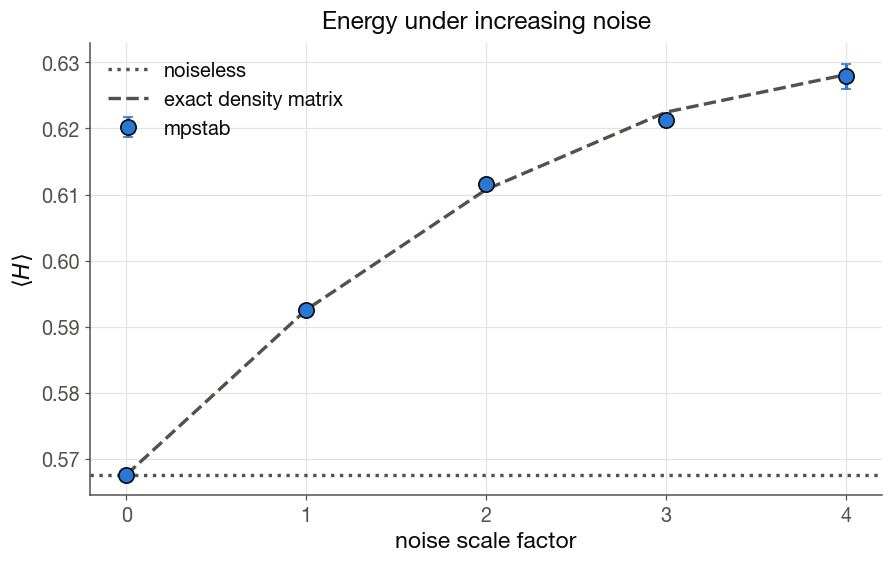

In [8]:
fig, ax = plt.subplots()
ax.axhline(ideal, color=COLORS["gray"], ls=":", label="noiseless")
ax.plot(factors, exacts, "--", color=COLORS["gray"], label="exact density matrix")
ax.errorbar(factors, [r.mean for r in results], yerr=[r.stderr for r in results],
            fmt="o", label="mpstab")
ax.set_xticks(factors)
ax.set_xlabel("noise scale factor")
ax.set_ylabel(r"$\langle H \rangle$")
ax.set_title("Energy under increasing noise")
ax.legend()
plt.show()

The noise model is a mix of stochastic and coherent errors, so the energy does not simply decay towards zero: the residual $ZZ$ coupling shifts the Ising angles and pushes the energy *up*. `mpstab` follows the exact curve at every strength.

## Beyond density matrices

`noisy_expectation` never builds a $4^n$ object: its cost is the number of sign patterns times the cost of one noiseless HSMPO evaluation. The same noise model therefore runs unchanged on long chains, where `max_bond_dimension` sets the accuracy of each evaluation.

We measure a local $Z_iZ_{i+1}$ in the middle of the chain. Only the gates and errors in its light cone can affect it, and `mpstab` drops all the others exactly, so the cost hardly depends on the chain length. A global observable, such as the full energy, has a light cone that grows with the chain, and costs more.

In [9]:
print(" n    noiseless   noisy               time")
for n in (16, 100):
    surrogate = HSMPO(ParametricKickedIsing(nqubits=n, n_steps=3, delta_h=0.2),
                      max_bond_dimension=32, progress=False)
    local = zz(n // 2, n)
    start = time.perf_counter()
    res = surrogate.noisy_expectation(local, noise, n_samples=500, seed=0)
    print(f"{n:3d}   {surrogate.expectation(local):+.4f}     {res.mean:+.4f} ± {res.stderr:.0e}"
          f"   {time.perf_counter() - start:4.1f} s")

 n    noiseless   noisy               time


 16   +0.1123     +0.1009 ± 2e-05    2.7 s


100   +0.1123     +0.1009 ± 2e-05   13.3 s


A 100-qubit density matrix would need $4^{100}$ entries. Because the light cone has a fixed size, both chains give the same value: the bulk value of an infinite chain.

## Summary

```python
noise = NoiseModel()
noise.add(DepolarizingError(1e-3))                 # after every gate
noise.add(PauliError({"ZZ": 5e-4}), gates.CNOT)    # correlated, on CNOTs
noise.add(CoherentError("ZZ", 0.02), gates.CNOT)   # residual coupling
noise.add(ReadoutError(0.01))                      # readout bit flips

noisy = hsmpo.noisy_expectation(obs, noise)        # noisy.mean, noisy.stderr
exact = noise.apply(circuit)                       # qibo density-matrix circuit
stronger = noise.scaled(2.0)                       # noise-strength sweeps
```

The "Non-unital noise simulation" tutorial adds relaxation, crosstalk, idle noise and preparation errors. The "Data-driven error mitigation" tutorial uses these noise models to learn how to correct noisy values.